# Task 4: Trend Analysis by Release Year

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("C:/Users/Admin/Downloads/Auspify Tech Internship/dataset_cleaned.csv")

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
df['release_year'].head()

0    2020
1    2021
2    2021
3    2021
4    1993
Name: release_year, dtype: int64

In [5]:
# Inspect data type and mising values
print(df['release_year'].dtype)
print(df['release_year'].isnull().sum())

int64
0


In [6]:
# Give earliest and latest year
print(df["release_year"].min(), df["release_year"].max())

1925 2021


## Step 2: Calculate Yearly Content Releases

In [7]:
# Count how many different years appear
print(df["release_year"].nunique())


74


In [8]:
# Calculate yearly content releases
yearly_counts = df['release_year'].value_counts()
print(yearly_counts)

release_year
2018    1146
2017    1030
2019    1030
2020     953
2016     901
        ... 
1966       1
1959       1
1925       1
1947       1
1961       1
Name: count, Length: 74, dtype: int64


In [9]:
df = df.sort_values("release_year")
yearly = df.groupby("release_year").size()
print(yearly.head())
print(yearly.tail())

release_year
1925    1
1942    2
1943    3
1944    3
1945    4
dtype: int64
release_year
2017    1030
2018    1146
2019    1030
2020     953
2021     592
dtype: int64


In [10]:
# Zoom in on recent years
yearly = df.groupby("release_year").size()
recent_years = yearly[yearly.index >= 2000]

print(len(recent_years))                       # how many years
print(recent_years.sum() / len(df) * 100)      # what % of all titles

22
94.02730375426621


In [11]:
# Split by movie and Tv show
yearly_type = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)
print(yearly_type.loc[2014:2021])

type          Movie  Tv Show
release_year                
2014            264       88
2015            396      159
2016            658      243
2017            765      265
2018            767      379
2019            633      397
2020            517      436
2021            277      315


In [12]:
print(yearly.idxmax(), yearly.max())                  # peak year and its count
print((df["release_year"] < 2000).sum())              # titles before 2000
print((df["release_year"] >= 2015).mean() * 100)      # % released 2015 or later

2018 1146
525
70.61433447098976


## Step 3: Identify Growth and Decline Trends

In [13]:
# Year-over-year change
yoy = (yearly.pct_change() * 100).round(1)
print(yoy.loc[2012:2021])

release_year
2012    27.6
2013    21.2
2014    23.1
2015    57.7
2016    62.3
2017    14.3
2018    11.3
2019   -10.1
2020    -7.5
2021   -37.9
dtype: float64


### Interpretation
*Growth phase*: steady growth through 2010 to 2014, then a jump of about 58% in 2015 and 62% in 2016.

*Peak*: `2018`, with `1,146` titles.

*Decline*: −10.1% in 2019 and −7.5% in 2020, about −16.8% below the peak by 2020. 2021 is excluded because it’s incomplete.

## Step 4: Visualizations

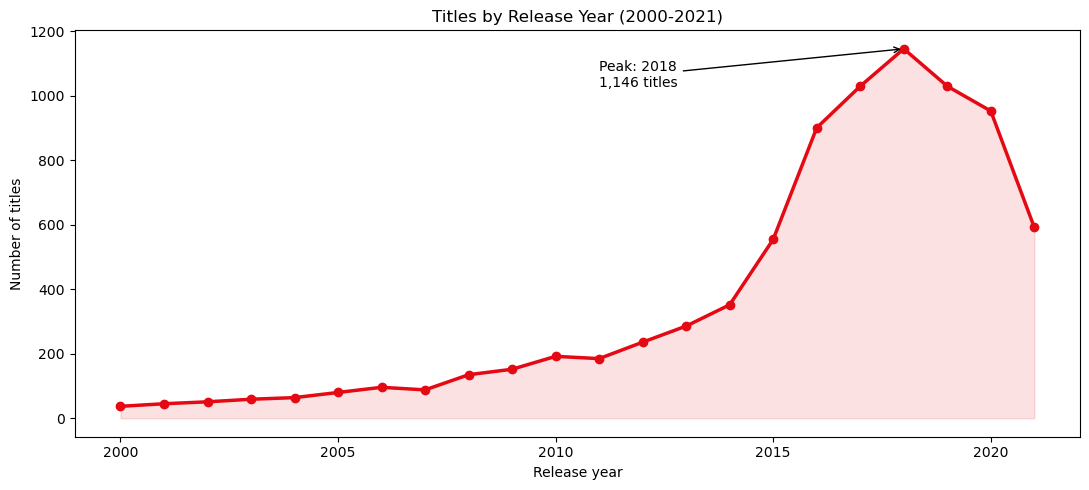

In [14]:
# Total tiltles by release year

recent_years = yearly[yearly.index >= 2000]
peak_year = yearly.idxmax()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(recent_years.index, recent_years.values, marker="o", color="#E50914", linewidth=2.5)
ax.fill_between(recent_years.index, recent_years.values, alpha=0.12, color="#E50914")
ax.annotate(f"Peak: {peak_year}\n{yearly.max():,} titles",
            (peak_year, yearly.max()),
            xytext=(peak_year - 7, yearly.max() - 120),
            arrowprops=dict(arrowstyle="->"))
ax.set(title="Titles by Release Year (2000-2021)", xlabel="Release year", ylabel="Number of titles")
plt.tight_layout()
plt.show()

### Interpretation
Output was low and steady until about `2010` `192` titles, then rose quickly to a peak of `1,146` titles in `2018`. Titles released from `2015` onwards make up about `70.6%` of the catalogue. After `2018` releases fell to `953` in `2020`. `2021` is a partial year (data ends in September), so its lower figure shouldn’t be read as a collapse.

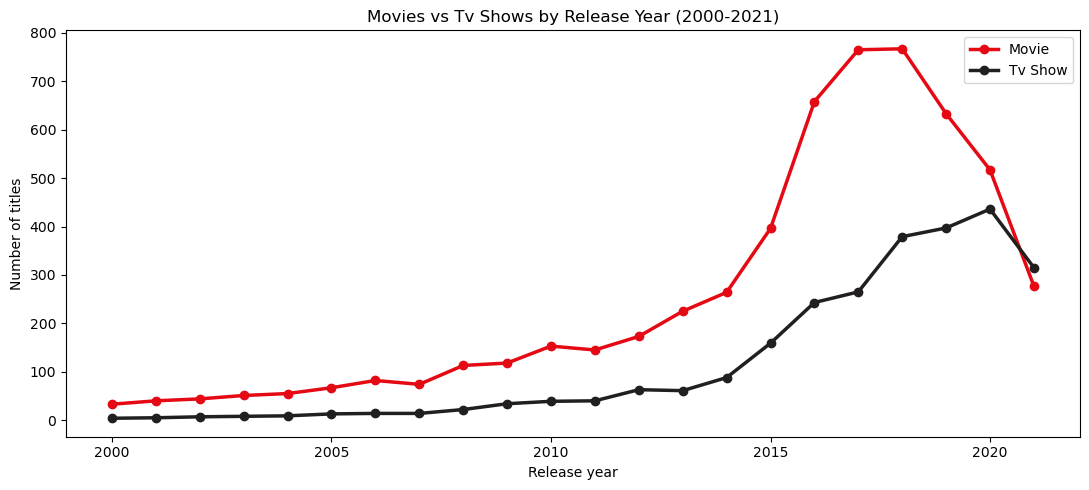

In [16]:
# Movies by TV Shows by Years
yt = yearly_type[yearly_type.index >= 2000]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yt.index, yt["Movie"], marker="o", linewidth=2.5, label="Movie", color="#E50914")
ax.plot(yt.index, yt["Tv Show"], marker="o", linewidth=2.5, label="Tv Show", color="#221F1F")
ax.set(title="Movies vs Tv Shows by Release Year (2000-2021)", xlabel="Release year", ylabel="Number of titles")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation
Movies outnumber TV Shows in every full year, but the gap narrows. TV Shows were about 25% of 2014 releases and about 46% in 2020. Movies peaked in 2018 at `767` and fell to `517` by `2020`, while TV Shows kept rising until 2020 (436). The 2021 crossover (315 TV Shows vs 277 movies) comes from an incomplete year, so it needs caution.

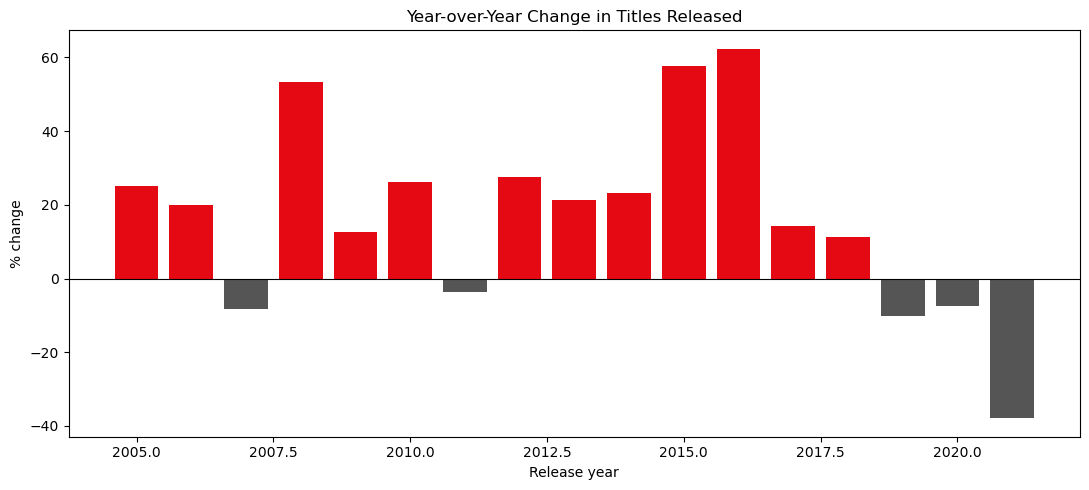

In [17]:
# Year-over-year change
yoy_plot = yoy[yoy.index >= 2005]

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#E50914" if v >= 0 else "#555555" for v in yoy_plot.values]
ax.bar(yoy_plot.index, yoy_plot.values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Year-over-Year Change in Titles Released", xlabel="Release year", ylabel="% change")
plt.tight_layout()
plt.show()

### Interpretation
The fastest growth was in `2015` `+57.7%` and `2016` `+62.3%`, when the catalogue was still small. Growth then slowed to `+14.3%` in `2017` and +11.3% in `2018`, and turned negative in `2019` `−10.1%` and `2020` `−7.5%`. Percentage growth falls as the base gets larger, which is why `2018` has the highest count but a modest growth rate. The `2021` bar `−37.9%` reflects a partial year.

## Step 5: Business Insights

1. Rapid expansion, then slowing: the catalogue is mostly recent, with a peak in 2018 and a decline after.

2. Shift towards TV Shows: the series share of releases rose from about 25% in 2014 to about 46% in 2020.

3. Recency: about 70.6% of titles are from 2015 onwards, and only 6% from before 2000. So the catalogue is mostly new content, with relatively little classic or older material.

# Task 5:  Content Rating & Genre Analysis

## Analyze Rating Categories

In [18]:
# Count each rating
df["type"] = df["type"].replace("Tv Show", "TV Show")   # same fix as before

rating_counts = df["rating"].value_counts()
rating_pct = (rating_counts / len(df) * 100).round(1)
print(pd.DataFrame({"titles": rating_counts, "percent": rating_pct}))
print(df["rating"].nunique(), df["rating"].isna().sum())

          titles  percent
rating                   
TV-MA       3205     36.5
TV-14       2157     24.5
TV-PG        861      9.8
R            799      9.1
PG-13        490      5.6
TV-Y7        333      3.8
TV-Y         306      3.5
PG           287      3.3
TV-G         220      2.5
NR            79      0.9
G             41      0.5
TV-Y7-FV       6      0.1
UR             3      0.0
NC-17          3      0.0
14 0


### Observation
The top two ratings, TV-MA and TV-14, cover 61.0% of all titles.

## Identify Most Common Genres

In [19]:
# Split and explode genres into individuals
genre_df = df.assign(genre=df["listed_in"].str.split(","))   # 1. split into a list
genre_df = genre_df.explode("genre")                          # 2. one row per genre
genre_df["genre"] = genre_df["genre"].str.strip()             # 3. remove stray spaces

print(len(df), len(genre_df))
print(genre_df["genre"].nunique())

8790 19294
42


In [20]:
# Count the genre
genre_counts = genre_df["genre"].value_counts()
genre_pct = (genre_counts / len(df) * 100).round(1)       # % of TITLES that carry the genre
print(pd.DataFrame({"titles": genre_counts, "percent": genre_pct}).head(10))

                          titles  percent
genre                                    
International Movies        2752     31.3
Dramas                      2426     27.6
Comedies                    1674     19.0
International TV Shows      1349     15.3
Documentaries                869      9.9
Action & Adventure           859      9.8
TV Dramas                    762      8.7
Independent Movies           756      8.6
Children & Family Movies     641      7.3
Romantic Movies              616      7.0


In [24]:
print(genre_df.head(10))

     show_id     type                                          title  \
421    s4251  TV Show              Pioneers: First Women Filmmakers*   
5698   s7791    Movie                                 Prelude to War   
5698   s7791    Movie                                 Prelude to War   
6037   s8206    Movie                           The Battle of Midway   
6037   s8206    Movie                           The Battle of Midway   
6510   s8764    Movie                WWII: Report from the Aleutians   
6422   s8661    Movie  Undercover: How to Operate Behind Enemy Lines   
6422   s8661    Movie  Undercover: How to Operate Behind Enemy Lines   
6491   s8740    Movie             Why We Fight: The Battle of Russia   
6230   s8437    Movie                              The Negro Soldier   

                         director        country  date_added  release_year  \
421                     Not Given       Pakistan  2018-12-30          1925   
5698                  Frank Capra  United States  2

In [25]:
# Top genres within each type
for t in ["Movie", "TV Show"]:
    print(t)
    print(genre_df[genre_df["type"] == t]["genre"].value_counts().head(5))

Movie
genre
International Movies    2752
Dramas                  2426
Comedies                1674
Documentaries            869
Action & Adventure       859
Name: count, dtype: int64
TV Show
genre
International TV Shows    1349
TV Dramas                  762
TV Comedies                573
Crime TV Shows             469
Kids' TV                   448
Name: count, dtype: int64


## Compare ratings across content types

In [26]:
# Cross tabulate rating and type
rating_type = pd.crosstab(df["rating"], df["type"])
print(rating_type)

type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


In [30]:
# Compare percentages not counts
rating_percentages = pd.crosstab(
    df['rating'],
    df['type'],
    normalize='columns'
) * 100

print(rating_percentages.round(1).sort_values("Movie", ascending=False))

type      Movie  TV Show
rating                  
TV-MA      33.7     42.9
TV-14      23.3     27.4
R          13.0      0.1
TV-PG       8.8     12.0
PG-13       8.0      0.0
PG          4.7      0.0
TV-Y7       2.3      7.3
TV-G        2.1      3.5
TV-Y        2.1      6.6
NR          1.2      0.2
G           0.7      0.0
TV-Y7-FV    0.1      0.0
NC-17       0.0      0.0
UR          0.0      0.0


In [31]:
# Compare only ratings both types share
tv_rated = df[df["rating"].str.startswith("TV-")]
print(tv_rated["type"].value_counts())       # Movies: 4,430 | TV Shows: 2,658

shared = pd.crosstab(tv_rated["rating"], tv_rated["type"], normalize="columns") * 100
print(shared.round(1))

type
Movie      4430
TV Show    2658
Name: count, dtype: int64
type      Movie  TV Show
rating                  
TV-14      32.2     27.5
TV-G        2.8      3.5
TV-MA      46.5     43.0
TV-PG      12.2     12.1
TV-Y        3.0      6.6
TV-Y7       3.1      7.3
TV-Y7-FV    0.1      0.0


### Observation: 
TV-MA is the most common rating for both types (33.7% of Movies, 42.9% of TV Shows). Among TV-rated titles only, TV-Y and TV-Y7 make up about 13.9% of TV Shows but about 6.1% of Movies.

### Interpretation: 
This suggests series are used more than films for young children’s content, while both types are mostly aimed at teens and adults.

R, PG-13 and PG ratings are almost exclusive to Movies, so the full comparison partly reflects two different rating systems. The TV-rated comparison avoids this but excludes 1,703 titles.

## Visualizations

In [33]:
import plotly.express as px

COLORS = {"Movie": "#E50914", "TV Show": "#221F1F"}

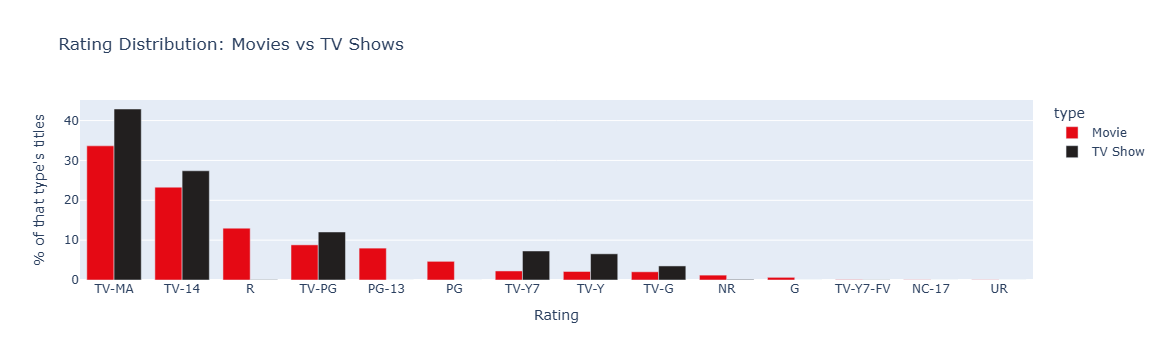

In [37]:
# Rating distribution by content type
rating_pct = pd.crosstab(df["rating"], df["type"], normalize="columns") * 100

# Plotly wants "long" format: one row per (rating, type) pair
rating_long = rating_pct.reset_index().melt(
    id_vars="rating", var_name="type", value_name="percent"
)
order = rating_pct.sort_values("Movie", ascending=False).index.tolist()

fig1 = px.bar(
    rating_long, x="rating", y="percent", color="type", barmode="group",
    color_discrete_map=COLORS, category_orders={"rating": order},
    title="Rating Distribution: Movies vs TV Shows",
    labels={"percent": "% of that type's titles", "rating": "Rating"},
)
fig1.show()
fig1.write_html("rating_distribution.html")

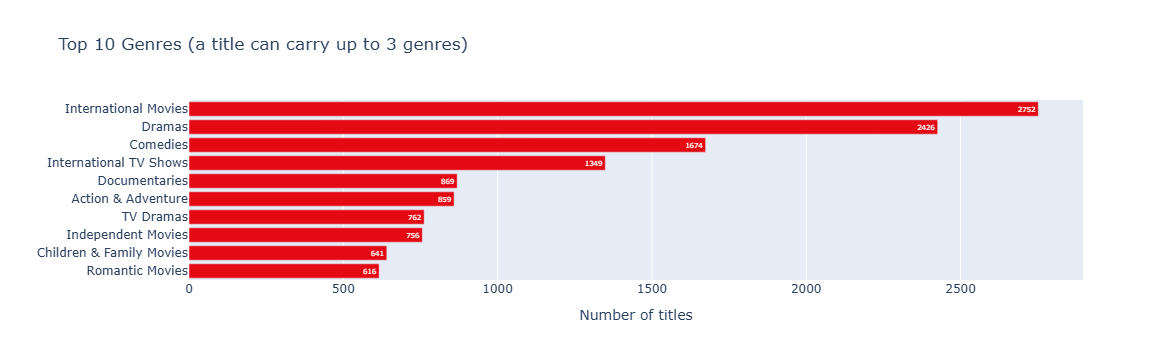

In [38]:
# Top 10 genres
top_genres = genre_counts.head(10).rename_axis("genre").reset_index(name="titles")

fig2 = px.bar(
    top_genres.sort_values("titles"),          # ascending, so the biggest ends up on top
    x="titles", y="genre", orientation="h", text="titles",
    title="Top 10 Genres (a title can carry up to 3 genres)",
    labels={"titles": "Number of titles", "genre": ""},
    color_discrete_sequence=["#E50914"],
)
fig2.show()
fig2.write_html("top_genres.html")

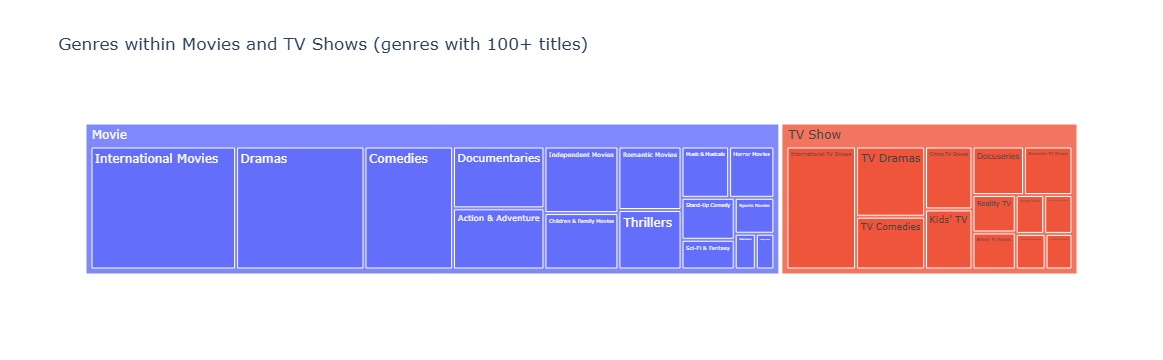

In [39]:
#Genres inside each content type
genre_type = genre_df.groupby(["type", "genre"]).size().reset_index(name="titles")
genre_type = genre_type[genre_type["titles"] >= 100]      # hide tiny genres so labels stay readable

fig3 = px.treemap(
    genre_type, path=["type", "genre"], values="titles",
    title="Genres within Movies and TV Shows (genres with 100+ titles)",
)
fig3.show()
fig3.write_html("genre_treemap.html")

## Business Insights

#### Insight 1: TV-MA is the most common rating

TV-MA accounts for 36.5% of all titles in your dataset, making it the largest rating category. This suggests that mature-rated content dominate a substantial share of the Netflix catalogue you analyzed.

#### Insight 2: TV-MA and TV-14 dominate the catalogue

Together, TV-MA (36.5%) and TV-14 (24.5%) account for 61% of titles. This indicates a strong representation of content carrying mature or teen-oriented ratings.

#### Insight 3: Children’s ratings lean towards TV Shows.

Among TV-rated titles, TV-Y and TV-Y7 together make up 13.9% of TV Shows and 6.1% of Movies.

#### Insight 4:
International Movies (31.3% of titles), Dramas (27.6%) and Comedies (19.0%) are the most common tags. Of the Movies, about 39.6% carry the Dramas tag

In [40]:
import os
print(os.getcwd())

C:\Users\Admin
